In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

df = pd.DataFrame({
    "City": [
        "Delhi", "Jaipur", "Ajmer", "Mumbai",
        "Pune", "Lucknow", "Bhopal", "Patna",
        "Ahmedabad", "Kota", "Jodhpur", "Indore"
    ],
    "Latitude": [
        28.61, 26.91, 26.45, 19.08,
        18.52, 26.85, 23.26, 25.59,
        23.02, 25.18, 26.24, 22.72
    ],
    "Longitude": [
        77.21, 75.79, 74.64, 72.88,
        73.86, 80.95, 77.41, 85.14,
        72.57, 75.83, 73.02, 75.86
    ],
    "Monthly_Sales": [
        95000, 68000, 25000, 120000,
        85000, 62000, 45000, 58000,
        78000, 30000, 35000, 72000
    ],
    "Customer_Demand": [
        950, 800, 750, 1200,
        1000, 900, 650, 850,
        900, 700, 600, 880
    ],
    "Existing_Stores": [
        12, 7, 2, 15, 8, 3, 3, 2, 6, 1, 2, 5
    ]
})

df.head()


,City,Latitude,Longitude,Monthly_Sales,Customer_Demand,Existing_Stores
0,Delhi,28.61,77.21,95000,950,12
1,Jaipur,26.91,75.79,68000,800,7
2,Ajmer,26.45,74.64,25000,750,2
3,Mumbai,19.08,72.88,120000,1200,15
4,Pune,18.52,73.86,85000,1000,8


In [ ]:

df["Demand_Per_Store"] = (
    df["Customer_Demand"] /
    df["Existing_Stores"]
)

df["Opportunity_Score"] = (
    df["Demand_Per_Store"] /
    df["Demand_Per_Store"].max() * 100
).round(2)

df = df.sort_values(
    "Opportunity_Score",
    ascending=False
)

display(df[[
    "City",
    "Customer_Demand",
    "Existing_Stores",
    "Demand_Per_Store",
    "Opportunity_Score"
]])


,City,Customer_Demand,Existing_Stores,Demand_Per_Store,Opportunity_Score
9,Kota,700,1,700.000000,100.00
7,Patna,850,2,425.000000,60.71
2,Ajmer,750,2,375.000000,53.57
10,Jodhpur,600,2,300.000000,42.86
5,Lucknow,900,3,300.000000,42.86
6,Bhopal,650,3,216.666667,30.95
11,Indore,880,5,176.000000,25.14
8,Ahmedabad,900,6,150.000000,21.43
4,Pune,1000,8,125.000000,17.86
1,Jaipur,800,7,114.285714,16.33


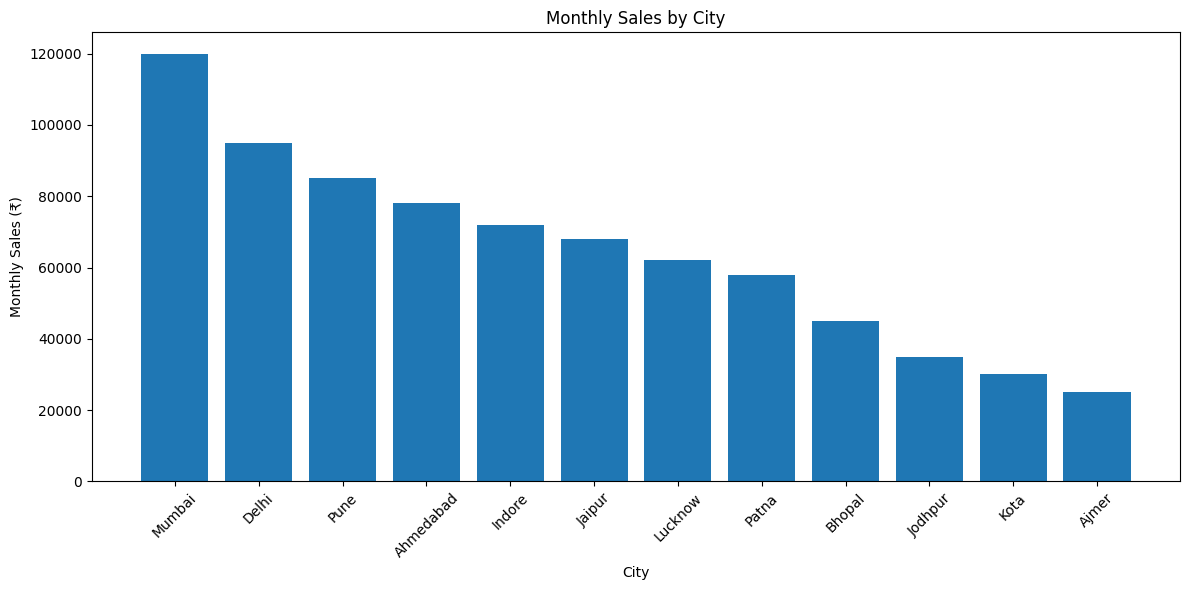

In [ ]:

sales_data = df.sort_values(
    "Monthly_Sales", ascending=False
)

plt.figure(figsize=(12, 6))
plt.bar(
    sales_data["City"],
    sales_data["Monthly_Sales"]
)
plt.title("Monthly Sales by City")
plt.xlabel("City")
plt.ylabel("Monthly Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

!pip -q install folium

import folium

india_map = folium.Map(
    location=[23.5, 78.5],
    zoom_start=5
)

for _, row in df.iterrows():
    folium.CircleMarker(
        location=[
            row["Latitude"],
            row["Longitude"]
        ],
        radius=max(
            5,
            min(18, row["Monthly_Sales"] / 8000)
        ),
        popup=(
            f"City: {row['City']}<br>"
            f"Sales: ₹{row['Monthly_Sales']:,}<br>"
            f"Demand: {row['Customer_Demand']}<br>"
            f"Stores: {row['Existing_Stores']}<br>"
            f"Opportunity Score: "
            f"{row['Opportunity_Score']}"
        ),
        color="blue",
        fill=True,
        fill_opacity=0.7
    ).add_to(india_map)

india_map


In [ ]:

# Illustrative screening criteria:
# Demand per store >= 200
# Monthly sales below ₹70,000

opportunities = df[
    (df["Demand_Per_Store"] >= 200) &
    (df["Monthly_Sales"] < 70000)
].sort_values(
    "Opportunity_Score",
    ascending=False
)

display(opportunities[[
    "City",
    "Monthly_Sales",
    "Customer_Demand",
    "Existing_Stores",
    "Demand_Per_Store",
    "Opportunity_Score"
]])


,City,Monthly_Sales,Customer_Demand,Existing_Stores,Demand_Per_Store,Opportunity_Score
9,Kota,30000,700,1,700.000000,100.00
7,Patna,58000,850,2,425.000000,60.71
2,Ajmer,25000,750,2,375.000000,53.57
10,Jodhpur,35000,600,2,300.000000,42.86
5,Lucknow,62000,900,3,300.000000,42.86
6,Bhopal,45000,650,3,216.666667,30.95
